<a href="https://colab.research.google.com/github/kuadoni/BA305-B3-Holiday-Movies/blob/main/HolidayMovies.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Brenda Wang: Data loading and cleaning

In [2]:
#Brenda: import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#Brenda: load the data

holiday_movies = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2023/2023-12-12/holiday_movies.csv')
holiday_movie_genres = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2023/2023-12-12/holiday_movie_genres.csv')


#Brenda: look at the first few rows
holiday_movies.head()

,tconst,title_type,primary_title,original_title,year,runtime_minutes,genres,simple_title,average_rating,num_votes,christmas,hanukkah,kwanzaa,holiday
0,tt0020356,movie,Sailor's Holiday,Sailor's Holiday,1929,58.0,Comedy,sailors holiday,5.4,55,False,False,False,True
1,tt0020823,movie,The Devil's Holiday,The Devil's Holiday,1930,80.0,"Drama,Romance",the devils holiday,6.0,242,False,False,False,True
2,tt0020985,movie,Holiday,Holiday,1930,91.0,"Comedy,Drama",holiday,6.3,638,False,False,False,True
3,tt0021268,movie,Holiday of St. Jorgen,Prazdnik svyatogo Yorgena,1930,83.0,Comedy,holiday of st jorgen,7.4,256,False,False,False,True
4,tt0021377,movie,Sin Takes a Holiday,Sin Takes a Holiday,1930,81.0,"Comedy,Romance",sin takes a holiday,6.1,740,False,False,False,True


In [4]:
#Brenda: get all column names
list(holiday_movies.columns)

['tconst',
 'title_type',
 'primary_title',
 'original_title',
 'year',
 'runtime_minutes',
 'genres',
 'simple_title',
 'average_rating',
 'num_votes',
 'christmas',
 'hanukkah',
 'kwanzaa',
 'holiday']

In [ ]:
#Brenda: drop original_title and simple_title columns
holiday_movies = holiday_movies.drop(columns=['original_title', 'simple_title'], errors='ignore')
holiday_movies.head()

,tconst,title_type,primary_title,year,runtime_minutes,genres,average_rating,num_votes,christmas,hanukkah,kwanzaa,holiday
0,tt0020356,movie,Sailor's Holiday,1929,58.0,Comedy,5.4,55,False,False,False,True
1,tt0020823,movie,The Devil's Holiday,1930,80.0,"Drama,Romance",6.0,242,False,False,False,True
2,tt0020985,movie,Holiday,1930,91.0,"Comedy,Drama",6.3,638,False,False,False,True
3,tt0021268,movie,Holiday of St. Jorgen,1930,83.0,Comedy,7.4,256,False,False,False,True
4,tt0021377,movie,Sin Takes a Holiday,1930,81.0,"Comedy,Romance",6.1,740,False,False,False,True


In [5]:
#Brenda: get summary info including non-null counts and data types
holiday_movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2265 entries, 0 to 2264
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           2265 non-null   object 
 1   title_type       2265 non-null   object 
 2   primary_title    2265 non-null   object 
 3   original_title   2265 non-null   object 
 4   year             2265 non-null   int64  
 5   runtime_minutes  2076 non-null   float64
 6   genres           2233 non-null   object 
 7   simple_title     2265 non-null   object 
 8   average_rating   2265 non-null   float64
 9   num_votes        2265 non-null   int64  
 10  christmas        2265 non-null   bool   
 11  hanukkah         2265 non-null   bool   
 12  kwanzaa          2265 non-null   bool   
 13  holiday          2265 non-null   bool   
dtypes: bool(4), float64(2), int64(2), object(6)
memory usage: 185.9+ KB


In [6]:
complete_cases = holiday_movies.dropna()
print(f"Number of completely non-null rows: {len(complete_cases)}")
print(f"Original rows: {len(holiday_movies)}")
print(f"Rows with at least one null: {len(holiday_movies) - len(complete_cases)}")

Number of completely non-null rows: 2063
Original rows: 2265
Rows with at least one null: 202


In [ ]:
# ryan: predictive feature selection and chronologal split

features = ["genres", "runtime_minutes", "title_type", "year"]
target = "average_rating"

data = holiday_movies[features + [target]].copy()
data = data.dropna(subset=[target])

# final test: 2021-23 films
# validation: 2018-20 films, used to choose model settings
# training: films released before 2018

train = data[data["year"] < 2018]
validation = data[data["year"].between(2018, 2020)]
test = data[data["year"] >= 2021]

X_train, y_train = train[features], train[target]
X_val, y_val = validation[features], validation[target]
X_test, y_test = test[features], test[target]

print("Training films:", len(train))
print("Validation films:", len(validation))
print("Test films:", len(test))

Training films: 1358
Validation films: 444
Test films: 463


In [ ]:
# ryan: preprossessing for predictive models

import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

def prepare_genres(values):
  # preserving missing genre information as an explicit catagory
  return values.fillna("MissingGenre").astype(str)

def split_genre(text):
  return [genre.strip() for genre in text.split(",") if genre.strip()]

def make_preprocessor():
  numerical = Pipeline([
      ("impute", SimpleImputer(strategy="median", add_indicator=True)),
      ("scale", StandardScaler()),
  ])

  genres = Pipeline([
      ("prepare", FunctionTransformer(prepare_genres, validate=False)),
      ("encode", CountVectorizer(
          tokenizer=split_genre,
          token_pattern=None,
          lowercase=False,
          binary=True,
      )),
  ])

  return ColumnTransformer([
      ("numerical", numerical, ["runtime_minutes", "year"]),
      ("format", OneHotEncoder(handle_unknown="ignore"), ["title_type"]),
      ("genres", genres, "genres"),
  ], sparse_threshold=0)

In [ ]:
# ryan: k-NN and regression-tree model comparison

import pandas as pd

from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import ParameterGrid
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

model_specs = {
    "k-NN": (
        KNeighborsRegressor(),
        {
            "model__n_neighbors": [5, 15, 30, 60],
            "model__weights": ["uniform", "distance"],
},
    ),
    "Regression tree": (
        DecisionTreeRegressor(random_state=305),
        {
            "model__max_depth": [2, 4, 6, None],
            "model__min_samples_leaf": [10, 30, 60],
        },
    ),
}

selected_models = {}
tuning_results = []

for name, (estimator, grid) in model_specs.items():
  best_mae = np.inf

  for settings in ParameterGrid(grid):
    pipeline = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", estimator),
    ])
    pipeline.set_params(**settings)
    pipeline.fit(X_train, y_train)

    train_mae = mean_absolute_error(y_train, pipeline.predict(X_train))
    val_mae = mean_absolute_error(y_val, pipeline.predict(X_val))

    tuning_results.append({
        "Model": name,
        "Settings": settings,
        "Training MAE": train_mae,
        "Validation MAE": val_mae,
    })

    if val_mae < best_mae:
      best_mae = val_mae
      selected_models[name] = {
          "settings": settings,
          "validation_mae": val_mae,
      }
tuning_table = pd.DataFrame(tuning_results)
display(tuning_table.sort_values(["Model", "Validation MAE"]))
print("Selected settings:", selected_models)

,Model,Settings,Training MAE,Validation MAE
16,Regression tree,"{'model__max_depth': 6, 'model__min_samples_le...",0.895129,0.757393
19,Regression tree,"{'model__max_depth': None, 'model__min_samples...",0.895129,0.757393
15,Regression tree,"{'model__max_depth': 6, 'model__min_samples_le...",0.872340,0.793191
13,Regression tree,"{'model__max_depth': 4, 'model__min_samples_le...",0.904879,0.799348
12,Regression tree,"{'model__max_depth': 4, 'model__min_samples_le...",0.908154,0.799850
17,Regression tree,"{'model__max_depth': None, 'model__min_samples...",0.787734,0.804935
14,Regression tree,"{'model__max_depth': 6, 'model__min_samples_le...",0.874701,0.807424
11,Regression tree,"{'model__max_depth': 4, 'model__min_samples_le...",0.913805,0.813542
8,Regression tree,"{'model__max_depth': 2, 'model__min_samples_le...",0.931440,0.818992
9,Regression tree,"{'model__max_depth': 2, 'model__min_samples_le...",0.931440,0.818992


Selected settings: {'k-NN': {'settings': {'model__n_neighbors': 60, 'model__weights': 'distance'}, 'validation_mae': 0.7635938646771514}, 'Regression tree': {'settings': {'model__max_depth': 6, 'model__min_samples_leaf': 60}, 'validation_mae': 0.7573928872708283}}


In [ ]:
# ryan: final evaluation on 2021-2023 films

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

# combine training and validation data after selecting settings
X_development = pd.concat([X_train, X_val])
y_development = pd.concat([y_train, y_val])

preferred_model = min(
    selected_models,
    key=lambda name: selected_models[name]["validation_mae"]
)
print("Preferred model based on validation", preferred_model)

results = []
final_models = {}
results = []
final_models = {}

def record_scores(name, predictions):
    results.append({
        "Model": name,
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test R Squared": r2_score(y_test, predictions),
    })

baseline = DummyRegressor(strategy="mean")
baseline.fit(np.zeros((len(y_development), 1)), y_development)

record_scores(
    "Mean rating baseline",
    baseline.predict(np.zeros((len(y_test), 1)))
)

for name, selection in selected_models.items():
    pipeline = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", clone(model_specs[name][0])),
    ])

    pipeline.set_params(**selection["settings"])
    pipeline.fit(X_development, y_development)

    final_models[name] = pipeline
    record_scores(name, pipeline.predict(X_test))

final_results = pd.DataFrame(results)
display(final_results.round(3))

Preferred model based on validation Regression tree


,Model,Test MAE,Test RMSE,Test R Squared
0,Mean rating baseline,0.793,1.068,-0.004
1,k-NN,0.775,1.049,0.033
2,Regression tree,0.779,1.052,0.027


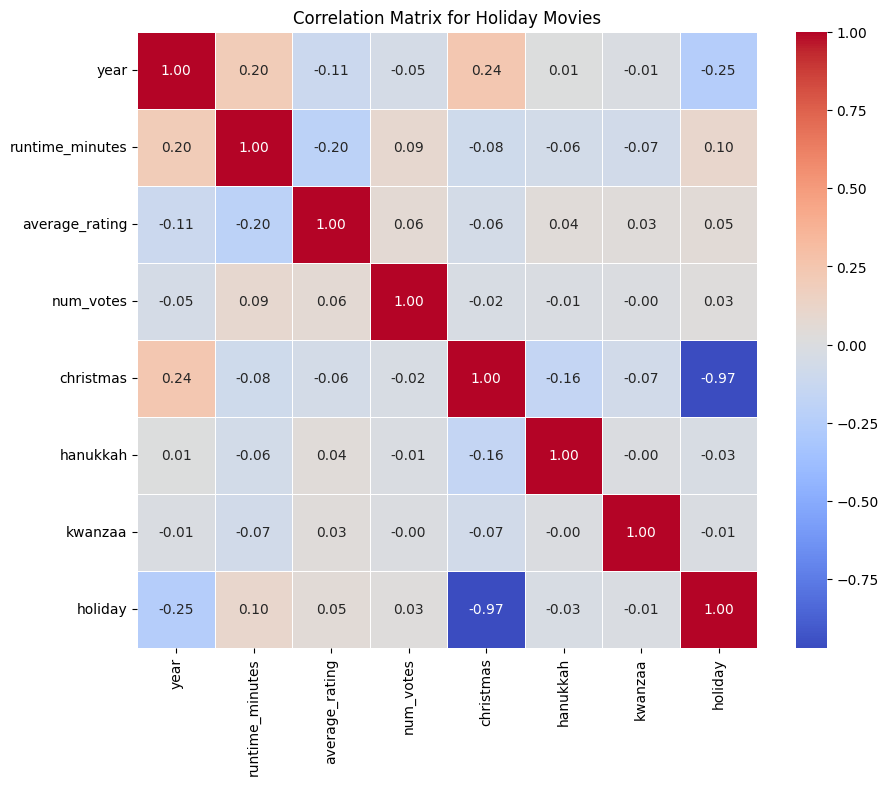

In [ ]:
#Brenda: get a correlation matrix

# Select numerical columns
numerical_cols = holiday_movies.select_dtypes(include=['float64', 'int64', 'bool'])

# Calculate correlation matrix
corr_matrix = numerical_cols.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix for Holiday Movies')
plt.show()

In [ ]:
#Brenda: combine original dataset with the genre dataset to split each movie into seperate genres

# Merge and drop the original comma-separated 'genres' column, then rename 'genres_split' to 'genres'
holiday_movies_combined = (
    pd.merge(holiday_movies, holiday_movie_genres, on='tconst', suffixes=('', '_split'))
    .drop(columns=['genres'])
    .rename(columns={'genres_split': 'genres'})
)
display(holiday_movies_combined.head())

,tconst,title_type,primary_title,year,runtime_minutes,average_rating,num_votes,christmas,hanukkah,kwanzaa,holiday,genres
0,tt0020356,movie,Sailor's Holiday,1929,58.0,5.4,55,False,False,False,True,Comedy
1,tt0020823,movie,The Devil's Holiday,1930,80.0,6.0,242,False,False,False,True,Drama
2,tt0020823,movie,The Devil's Holiday,1930,80.0,6.0,242,False,False,False,True,Romance
3,tt0020985,movie,Holiday,1930,91.0,6.3,638,False,False,False,True,Comedy
4,tt0020985,movie,Holiday,1930,91.0,6.3,638,False,False,False,True,Drama


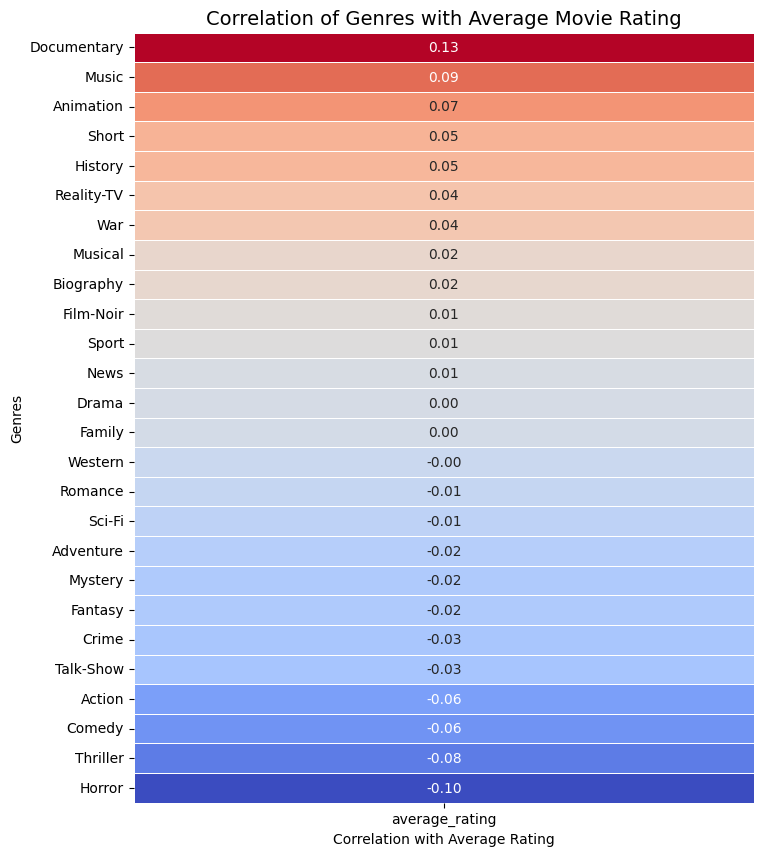

In [ ]:
#Brenda: Create genre dummy variables
genre_dummies = pd.get_dummies(holiday_movies_combined['genres'])

# Combine the dummy variables with average_rating from the combined dataset
combined_for_corr = pd.concat([holiday_movies_combined['average_rating'], genre_dummies], axis=1)

# Calculate correlation of all features (including genre dummies) with average_rating
genre_rating_corr = combined_for_corr.corr()['average_rating'][genre_dummies.columns]

# Sort the correlations for better visualization
genre_rating_corr = genre_rating_corr.sort_values(ascending=False).to_frame()

# Plot as a heatmap targeting only average_rating
plt.figure(figsize=(8, 10))
sns.heatmap(genre_rating_corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=False, linewidths=0.5)
plt.title('Correlation of Genres with Average Movie Rating', fontsize=14)
plt.ylabel('Genres')
plt.xlabel('Correlation with Average Rating')
plt.show()

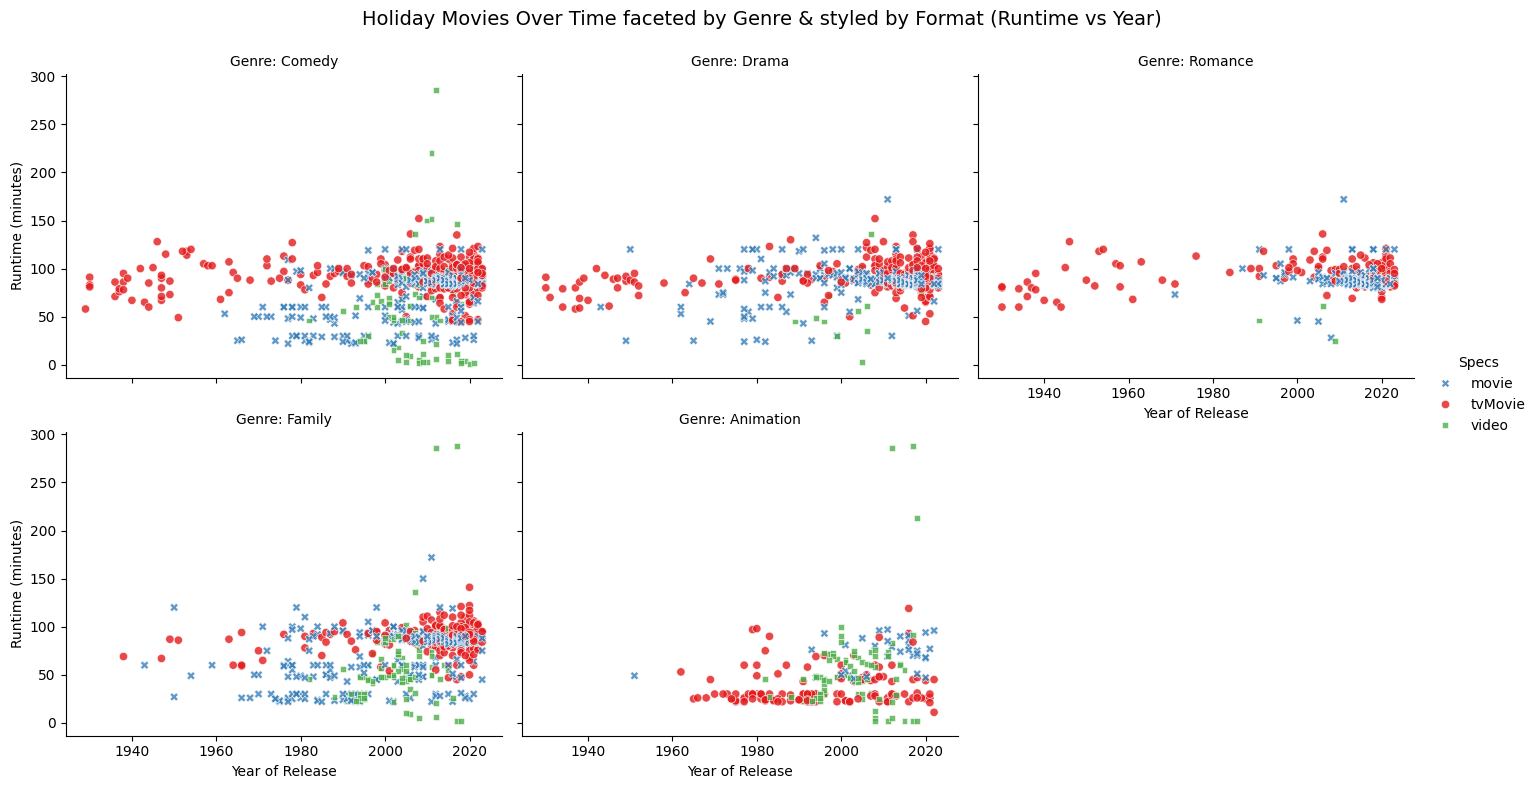

In [ ]:
#brenda: scatterplot to see movies across time when considering genre (top 5), runtime, and release format
import matplotlib.pyplot as plt
import seaborn as sns

# Filter to the top 5 most common genres
top_genres = holiday_movies_combined['genres'].value_counts().nlargest(5).index
filtered_data = holiday_movies_combined[holiday_movies_combined['genres'].isin(top_genres)]

# Create a faceted scatterplot grid grouped by Genre
g = sns.FacetGrid(
    filtered_data,
    col="genres",
    col_wrap=3,
    height=4,
    aspect=1.2
)

# Map Year on X-axis, Runtime on Y-axis, style and hue by Title Type (Format) with Set1 color palette for high contrast
g.map_dataframe(
    sns.scatterplot,
    x="year",
    y="runtime_minutes",
    hue="title_type",
    style="title_type",
    palette="Set1",
    alpha=0.8
)

g.add_legend(title="Specs")
g.set_titles("Genre: {col_name}")
g.set_axis_labels("Year of Release", "Runtime (minutes)")

plt.subplots_adjust(top=0.9)
g.fig.suptitle('Holiday Movies Over Time faceted by Genre & styled by Format (Runtime vs Year)', fontsize=14)
plt.show()

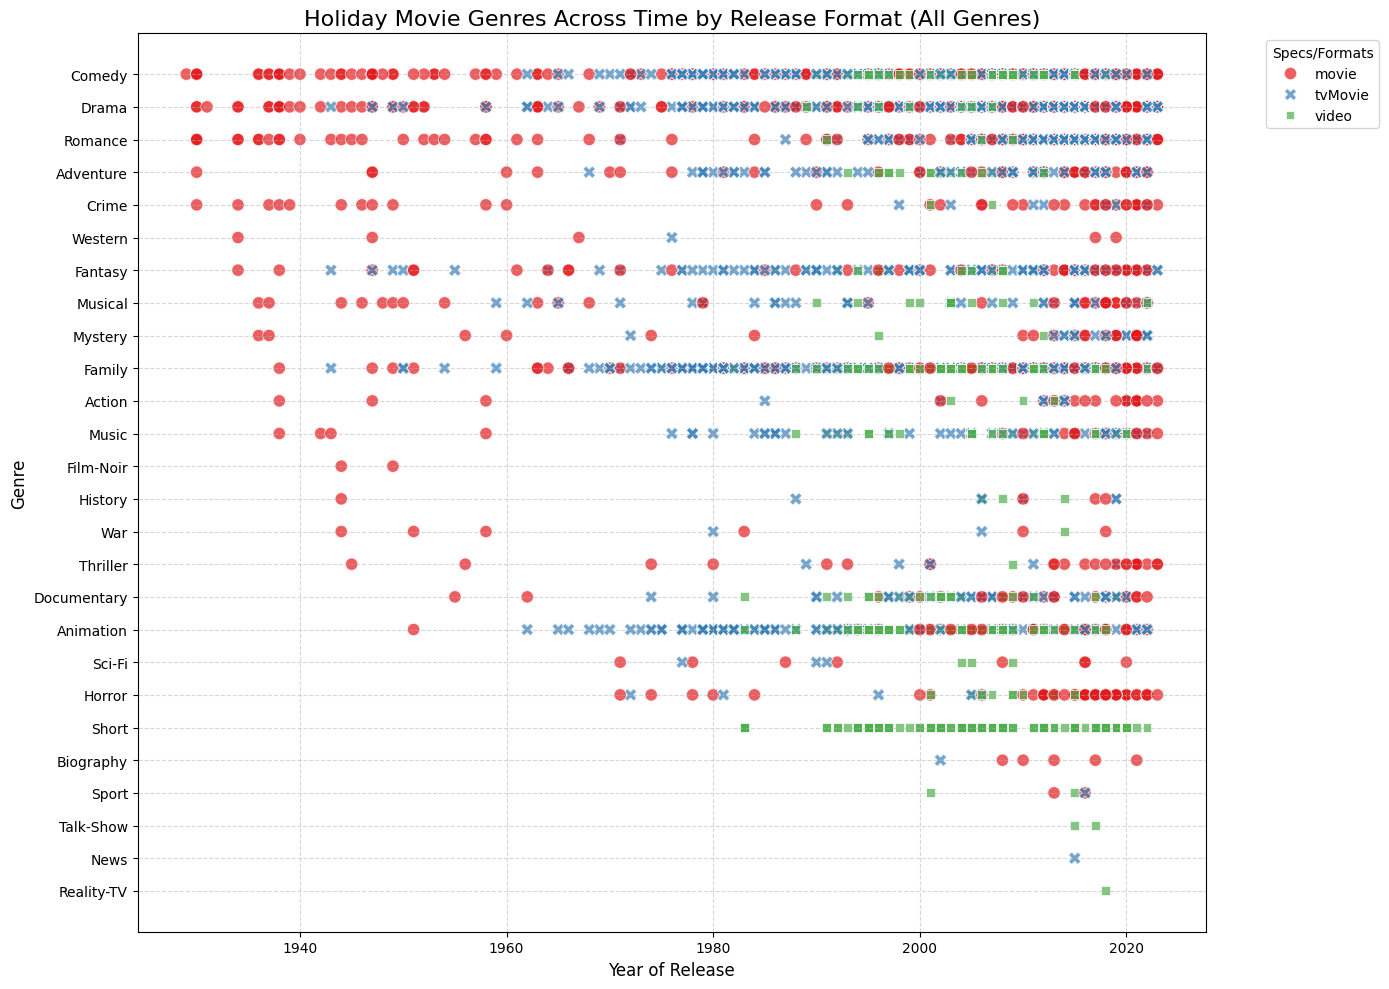

In [ ]:
#brenda: scatterplot to see all genres across time

plt.figure(figsize=(14, 10))

sns.scatterplot(
    data=holiday_movies_combined,
    x="year",
    y="genres",
    hue="title_type",
    style="title_type",
    palette="Set1",
    alpha=0.7,
    s=80
)

plt.title("Holiday Movie Genres Across Time by Release Format (All Genres)", fontsize=16)
plt.xlabel("Year of Release", fontsize=12)
plt.ylabel("Genre", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Specs/Formats", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

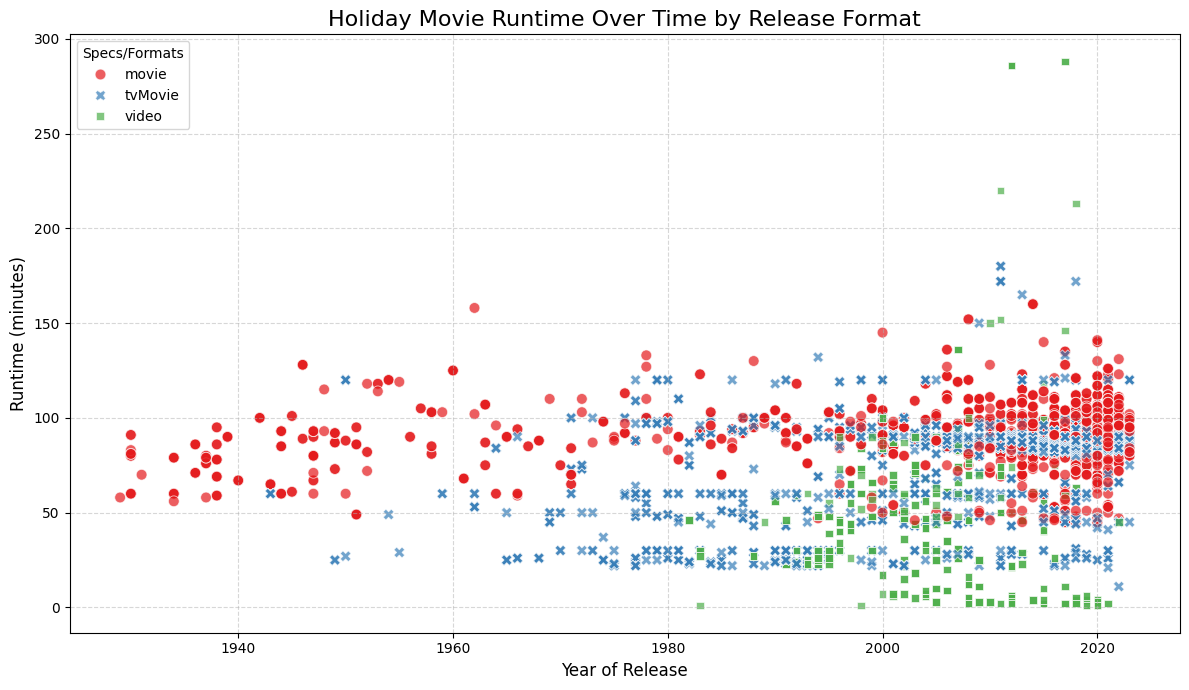

In [ ]:
#brenda: scatterplot to see runtime across time

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=holiday_movies_combined,
    x="year",
    y="runtime_minutes",
    hue="title_type",
    style="title_type",
    palette="Set1",
    alpha=0.7,
    s=60
)

plt.title("Holiday Movie Runtime Over Time by Release Format", fontsize=16)
plt.xlabel("Year of Release", fontsize=12)
plt.ylabel("Runtime (minutes)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Specs/Formats")
plt.tight_layout()
plt.show()

In [ ]:
#sam: pca data setup

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_numeric = holiday_movies[['year', 'runtime_minutes', 'average_rating', 'num_votes']].dropna(how='any')
pca_clean = holiday_movies.loc[pca_numeric.index].reset_index(drop=True).copy()

# every movie has at least 10 imdb votes, so log is defined.
pca_clean['log_votes'] = np.log(pca_clean['num_votes'])

# multi genre movie is used as a descriptive coloring variable, not a pca input.
pca_clean['romance_group'] = np.where(
    pca_clean['genres'].isna(), 'Missing genre',
    np.where(pca_clean['genres'].str.contains('Romance', na=False),
             'Romance', 'Other genres')
)

pca_variables = ['year', 'runtime_minutes', 'average_rating', 'log_votes']
pca_mdf = pca_clean[pca_variables]

print('original number of films:', len(holiday_movies))
print('number retained for PCA:', len(pca_clean))
print('number excluded for missing values:', len(holiday_movies) - len(pca_clean))
print('PCA variables:', pca_variables)
pca_mdf.head()

original number of films: 2265
number retained for PCA: 2076
number excluded for missing values: 189
PCA variables: ['year', 'runtime_minutes', 'average_rating', 'log_votes']


,year,runtime_minutes,average_rating,log_votes
0,1929,58.0,5.4,4.007333
1,1930,80.0,6.0,5.488938
2,1930,91.0,6.3,6.458338
3,1930,83.0,7.4,5.545177
4,1930,81.0,6.1,6.606650


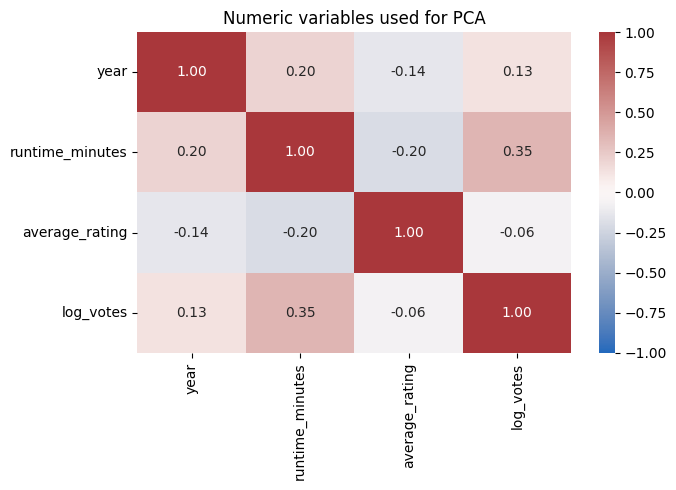

Scaled mean and standard deviation
      year  runtime_minutes  average_rating  log_votes
mean  -0.0              0.0            -0.0       -0.0
std    1.0              1.0             1.0        1.0


In [ ]:
#sam: pca correlation & scaling

pca_corr = pca_mdf.corr()
plt.figure(figsize=(7,5))
sns.heatmap(pca_corr, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='vlag')
plt.title('Numeric variables used for PCA')
plt.tight_layout()
plt.show()

pca_scaler = StandardScaler()
pca_scaled_df = pd.DataFrame(
  pca_scaler.fit_transform(pca_mdf), columns=pca_mdf.columns
)
print('Scaled mean and standard deviation')
print(pca_scaled_df.agg(['mean', 'std']).round(3))

In [ ]:
#sam pca continue

pca_model = PCA(n_components=4)
pca_scores = pca_model.fit_transform(pca_scaled_df)
pca_pc_names = ['pc1','pc2','pc3','pc4']
pca_scores_df = pd.DataFrame(pca_scores, columns=pca_pc_names)

pca_summary_df = pd.DataFrame({
    'Eigenvalue':pca_model.explained_variance_,
    '% of variance': pca_model.explained_variance_ratio_*100,
    'Cumulative %': np.cumsum(pca_model.explained_variance_ratio_)*100
},index=pca_pc_names)

print(pca_summary_df.round(3))

     Eigenvalue  % of variance  Cumulative %
pc1       1.566         39.125        39.125
pc2       0.959         23.952        63.077
pc3       0.854         21.348        84.426
pc4       0.623         15.574       100.000


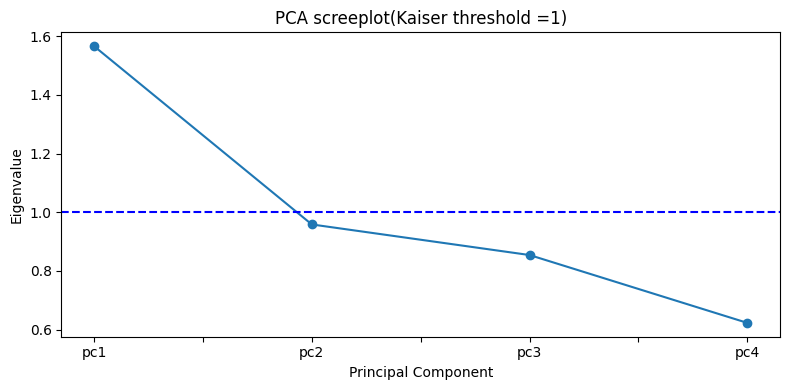

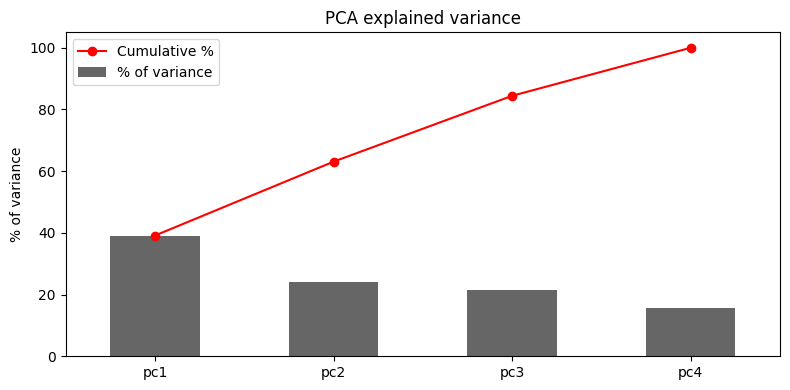

In [ ]:
#sam screeplot and cumulative variance

ax = pca_summary_df['Eigenvalue'].plot(marker='o',figsize=(8,4))
ax.axhline(y=1, color='blue',linestyle='--')
ax.set_title('PCA screeplot(Kaiser threshold =1)')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Eigenvalue')
plt.tight_layout()
plt.show()

ax=pca_summary_df['% of variance'].plot.bar(figsize=(8,4),color='0.4')
pca_summary_df['Cumulative %'].plot(marker='o',color='red',ax=ax)
ax.set_ylabel('% of variance')
ax.set_title('PCA explained variance')
ax.legend(['Cumulative %','% of variance'])
plt.tight_layout()
plt.show()

                   pc1    pc2    pc3    pc4
year             0.549 -0.317  0.770 -0.071
runtime_minutes  0.772  0.182 -0.159  0.588
average_rating  -0.488  0.703  0.474  0.207
log_votes        0.656  0.574 -0.104 -0.479


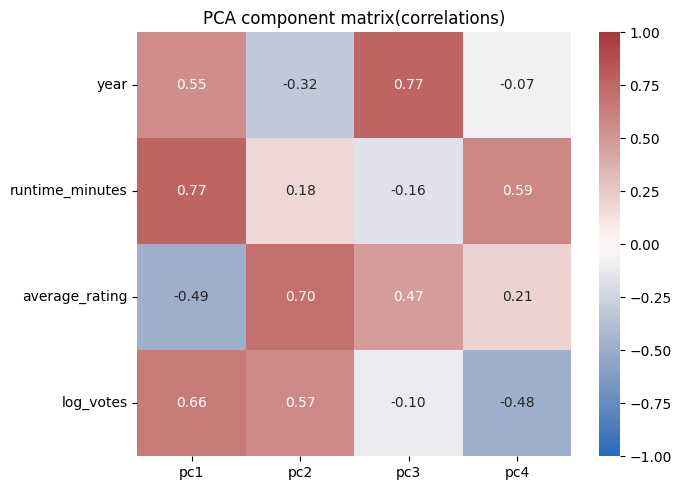

In [ ]:
#sam component matrix

pca_loadings_df = pd.concat([pca_scores_df, pca_scaled_df,],axis=1).corr().loc[
    pca_mdf.columns, pca_pc_names
]
print(pca_loadings_df.round(3))
plt.figure(figsize=(7,5))
sns.heatmap(pca_loadings_df, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='vlag')
plt.title('PCA component matrix(correlations)')
plt.tight_layout()
plt.show()

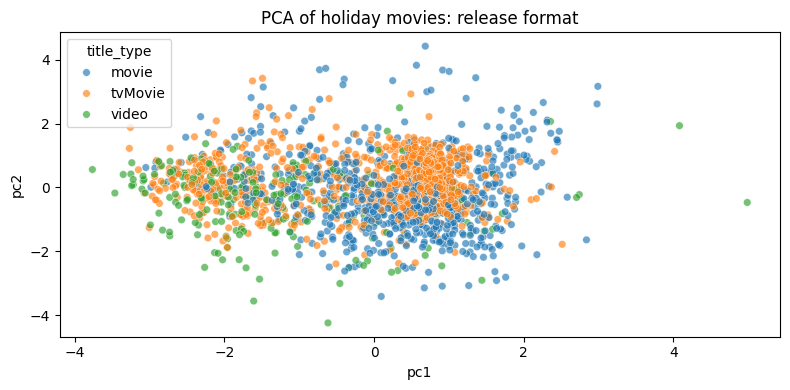

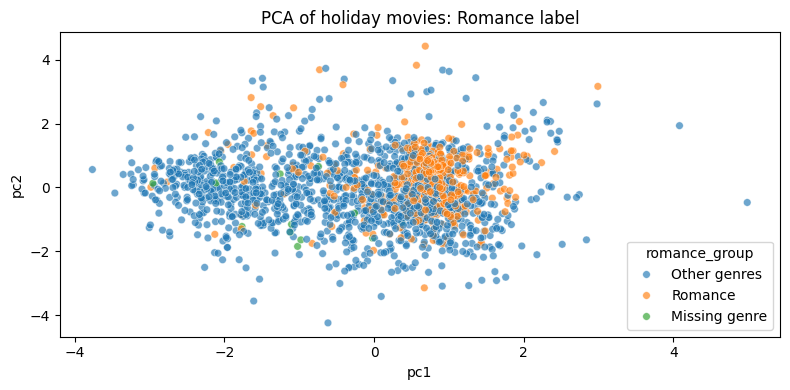

In [ ]:
#sam pca scores

pca_results = pd.concat([pca_clean, pca_scores_df],axis=1)

plt.figure(figsize=(8,4))
sns.scatterplot(data=pca_results, x='pc1', y='pc2', hue='title_type', alpha=0.65, s=30)
plt.title('PCA of holiday movies: release format')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,4))
sns.scatterplot(data=pca_results, x='pc1', y='pc2', hue='romance_group', alpha=0.65, s=30)
plt.title('PCA of holiday movies: Romance label')
plt.tight_layout()
plt.show()

In [ ]:
#sam summaries

print('PCA scores by title type (group ceneter):')
print(pca_results.groupby('title_type')[['pc1','pc2']].mean().round(3))
print('\nPCA scores by Romance label (group center):')
print(pca_results.groupby('romance_group')[['pc1','pc2']].mean().round(3))
print('\nNumber of films in PCA by title type:')
print(pca_results['title_type'].value_counts())
print('\nProportion of variation shown in pc1-pc2 scatter:')
print(round(pca_summary_df.loc[['pc1','pc2'],'% of variance'].sum(),1),'%')

PCA scores by title type (group ceneter):
              pc1    pc2
title_type              
movie       0.294 -0.151
tvMovie     0.056  0.183
video      -1.199 -0.416

PCA scores by Romance label (group center):
                 pc1    pc2
romance_group              
Missing genre -1.156 -0.662
Other genres  -0.323 -0.102
Romance        0.654  0.211

Number of films in PCA by title type:
title_type
tvMovie    1120
movie       726
video       230
Name: count, dtype: int64

Proportion of variation shown in pc1-pc2 scatter:
63.1 %
